# Лабораторна робота 4

**Виконав:** Бугайчук Василь 

**Група:** КМ-51
# Мета роботи:

Розробити програмний засіб, який здійснює центральну проєкцію зображення на одній площині та відображує її на іншій площині і зберігає зображення в одному з графічних форматів.



 

# Хід роботи

- Дослідити математичні методи перспективних проєкцій.

- Використати перетворений датасет з лабораторної роботи №3 поклавши координату z = 100

- Скачати файл з датасетом. Файл в текстовому форматі містить пари цілих чисел які є координатами точок. 

# Необхідно написати програму будь якою мовою з використанням будь яких бібліотек яка:

1. Зчитує датасет з файлу;
2. Знаходить матрицю центральної проекції з точкою сходження (540; 960)
3. Розраховує новий датасет зпроектованої площини 
4. Встановлює розміри вікна (полотна – canvas size) 960х540пкс;
5. Відображає новий датасет;
6. Виводить результати у файли будь-якого графічного формату.

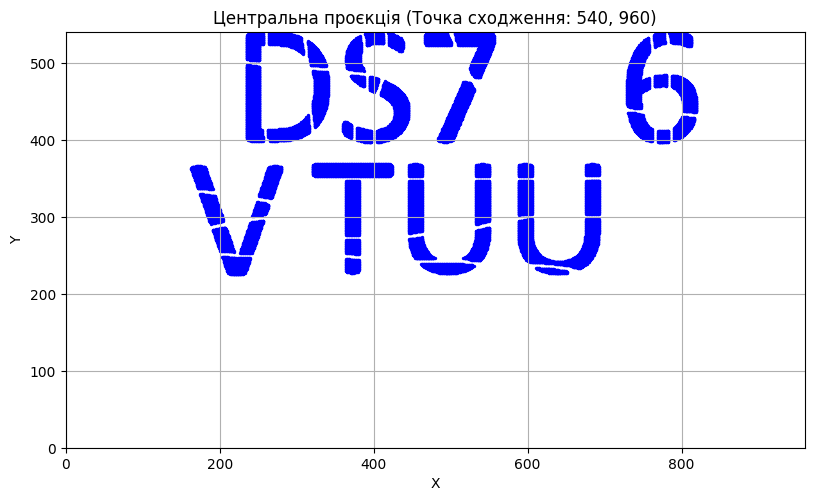

Файл успішно збережено як central_projection_result.png


In [ ]:
import math
import matplotlib.pyplot as plt

# 1. Зчитуємо датасет з файлу
  
with open("DS7.txt", 'r') as file:
    data = file.read().splitlines()

x_coords = []
y_coords = []

for line in data:
    if line.strip():
        parts = line.split()
        if len(parts) >= 2:
            x_coords.append(float(parts[0]))
            y_coords.append(float(parts[1]))

# 2 & 3. Параметри центральної проєкції
z_val = 100.0          # Задана координата z за умовами завдання
xc, yc = 540.0, 960.0  # Точка сходження (центр проєкції)
d = 500.0              # Фокусна відстань (параметр проєкції)

new_x = []
new_y = []

for x, y in zip(x_coords, y_coords):
    # Формула центральної (перспективної) проєкції відносно точки сходження (xc, yc)
    factor = d / (d + z_val)
    x_proj = xc + (x - xc) * factor
    y_proj = yc + (y - yc) * factor
    
    new_x.append(x_proj)
    new_y.append(y_proj)

# 4. Встановлюємо розміри вікна (полотна – canvas size) 960x540 пкс

plt.figure(figsize=(9.6, 5.4), dpi=100)

# 5. Відображаємо новий датасет
plt.scatter(new_x, new_y, color='blue', s=2)

# Налаштування осей під розміри полотна
plt.xlim(0, 960)
plt.ylim(0, 540)
plt.gca().set_aspect('equal', adjustable='box')

plt.title("Центральна проєкція (Точка сходження: 540, 960)")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# 6. Виводимо результати у файл графічного формату
output_filename = 'central_projection_result.png'
plt.savefig(output_filename, dpi=100, bbox_inches='tight')

# Показуємо графік
plt.show()
print(f"Файл успішно збережено як {output_filename}")